# Workshop-3: Streaming ETL with Apache Kafka and Machine Learning
## Part A — Step 3: Feature Engineering & Preprocessing Pipeline

### Objective
Prepare and engineer features for predicting the World Happiness Score (`actual_happiness_score`) using the harmonized historical dataset (`happiness_cleaned.csv` generated in Step 2).

Specifically, this notebook covers:
1. **Data Ingestion & Integrity Verification**: Load the harmonized dataset from `../data/processed/happiness_cleaned.csv`.
2. **Exploratory Relationship Analysis**: Compute correlation matrices, generate heatmaps, and visualize scatter plots with regression trends for all candidate features against the target.
3. **Feature Selection & Target Leakage Prevention**:
   - Select the 6 core socioeconomic drivers: `gdp`, `family`, `health`, `freedom`, `generosity`, and `corruption`.
   - Explicitly justify the exclusion of entity identifiers (`country`) and temporal markers (`year`).
   - Confirm strict avoidance of target leakage (no rank, no Dystopia residuals, target strictly isolated).
4. **Reproducible Preprocessing & Pipeline Architecture**:
   - Design a `scikit-learn` preprocessing pipeline using `StandardScaler` to ensure numerical features have zero mean and unit variance.
   - Establish the exact feature ordering contract required downstream by the Kafka streaming inference consumer.

---
## 1. Environment Setup & Data Ingestion
We load the clean harmonized dataset produced in Step 2 and verify its dimensions and integrity.

In [1]:
import sys
import asyncio
if sys.platform == "win32":
    try:
        asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())
    except Exception:
        pass

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Configure graphics and pandas display
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

DATA_PATH = Path("../data/processed/happiness_cleaned.csv") if Path("../data/processed/happiness_cleaned.csv").exists() else Path("data/processed/happiness_cleaned.csv")
print(f"Loading cleaned data from: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded. Shape: {df.shape}")
assert df.shape == (782, 9), f"Expected (782, 9), got {df.shape}"
assert df.isna().sum().sum() == 0, "Dataset contains unexpected missing values!"

df.head(5)

C:\Users\juand\AppData\Local\Temp\ipykernel_33028\2505167115.py:5: DeprecationWarning: 'asyncio.WindowsSelectorEventLoopPolicy' is deprecated and slated for removal in Python 3.16
  asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())
C:\Users\juand\AppData\Local\Temp\ipykernel_33028\2505167115.py:5: DeprecationWarning: 'asyncio.set_event_loop_policy' is deprecated and slated for removal in Python 3.16
  asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())


Loading cleaned data from: C:\Users\juand\Desktop\mis_cosas\uao\etl\workshops\workshop-3\data\processed\happiness_cleaned.csv
Dataset successfully loaded. Shape: (782, 9)


,country,year,gdp,family,health,freedom,generosity,corruption,actual_happiness_score
0,Switzerland,2015,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,7.587
1,Iceland,2015,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,7.561
2,Denmark,2015,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,7.527
3,Norway,2015,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,7.522
4,Canada,2015,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,7.427


---
## 2. Exploratory Relationship Analysis
We examine the statistical properties of the candidate explanatory factors and their linear correlation with `actual_happiness_score`.

In [2]:
# Summary statistics for features and target
NUMERICAL_COLS = ["gdp", "family", "health", "freedom", "generosity", "corruption", "actual_happiness_score"]

stats_df = df[NUMERICAL_COLS].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
stats_df["skewness"] = df[NUMERICAL_COLS].skew()
stats_df = stats_df.round(4)
stats_df

,count,mean,std,min,25%,50%,75%,max,skewness
gdp,782.0,0.9160,0.4073,0.000,0.6065,0.9822,1.2362,2.0960,-0.3186
family,782.0,1.0784,0.3295,0.000,0.8694,1.1247,1.3272,1.6440,-0.6846
health,782.0,0.6124,0.2483,0.000,0.4402,0.6473,0.8080,1.1410,-0.5012
freedom,782.0,0.4111,0.1529,0.000,0.3098,0.4310,0.5310,0.7240,-0.5213
generosity,782.0,0.2186,0.1223,0.000,0.1300,0.2020,0.2788,0.8381,1.0444
corruption,782.0,0.1257,0.1060,0.000,0.0542,0.0910,0.1562,0.5519,1.5128
actual_happiness_score,782.0,5.3790,1.1275,2.693,4.5098,5.3220,6.1895,7.7690,0.0359


### 2.1 Pearson Correlation Matrix & Target Correlation Ranking
Evaluating pairwise linear correlations allows us to quantify the strength and direction of each feature's association with national happiness.

Feature Ranking by Correlation with Target:


,Pearson Correlation with actual_happiness_score
gdp,0.7893
health,0.7425
family,0.6488
freedom,0.5513
corruption,0.4002
generosity,0.1376


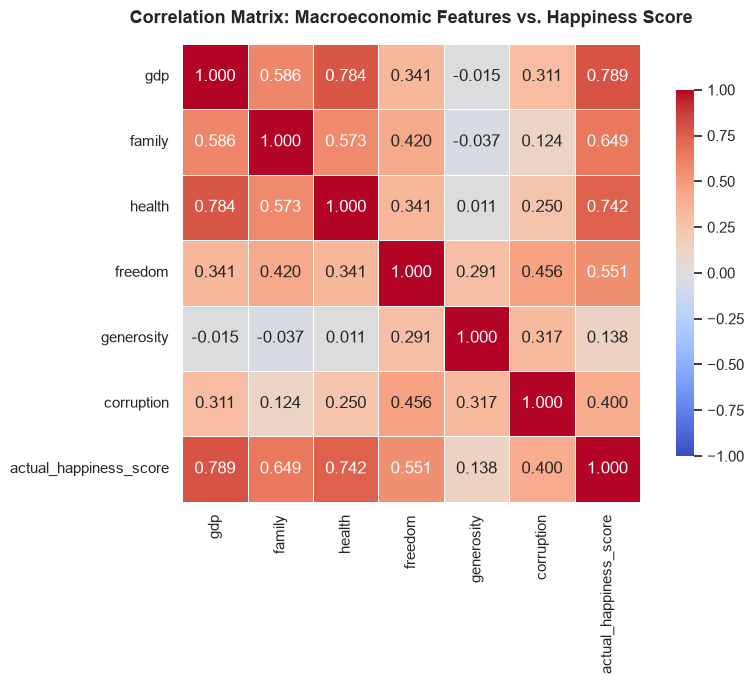

In [3]:
corr_matrix = df[NUMERICAL_COLS].corr()

# Ranking features by absolute correlation with the target
target_corr = corr_matrix[["actual_happiness_score"]].drop("actual_happiness_score").sort_values(
    by="actual_happiness_score", ascending=False
)
target_corr.columns = ["Pearson Correlation with actual_happiness_score"]

print("Feature Ranking by Correlation with Target:")
display(target_corr.round(4))

# Plot Correlation Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix: Macroeconomic Features vs. Happiness Score", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

### 2.2 Bivariate Relationships: Explanatory Features vs. Happiness Score
Visual inspection of scatter plots with fitted linear regression lines confirms the empirical relationship between each factor and the target score.

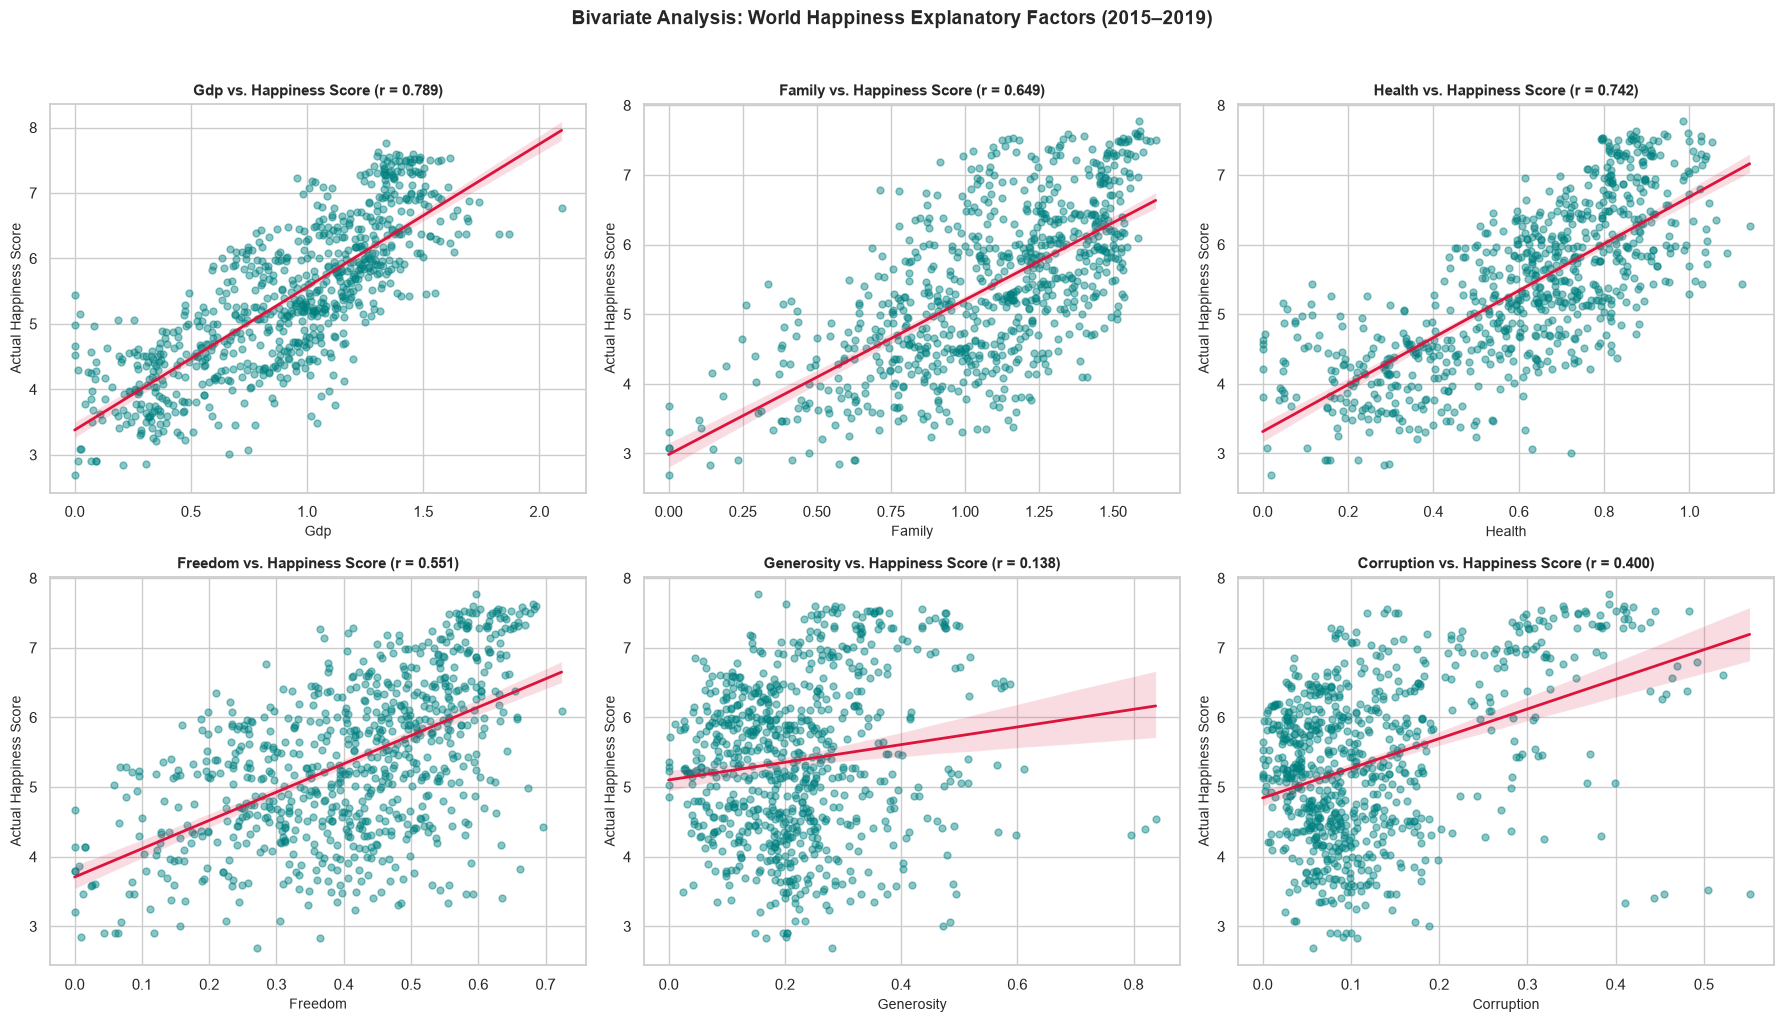

In [4]:
FEATURE_COLS = ["gdp", "family", "health", "freedom", "generosity", "corruption"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, feature in enumerate(FEATURE_COLS):
    sns.regplot(
        data=df,
        x=feature,
        y="actual_happiness_score",
        ax=axes[idx],
        scatter_kws={"alpha": 0.45, "color": "teal", "s": 25},
        line_kws={"color": "crimson", "linewidth": 2}
    )
    r_val = target_corr.loc[feature, "Pearson Correlation with actual_happiness_score"]
    axes[idx].set_title(f"{feature.capitalize()} vs. Happiness Score (r = {r_val:.3f})", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel(feature.capitalize(), fontsize=10)
    axes[idx].set_ylabel("Actual Happiness Score", fontsize=10)

plt.suptitle("Bivariate Analysis: World Happiness Explanatory Factors (2015–2019)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 3. Feature Selection & Target Leakage Prevention

### 3.1 Selected Features ($\mathbf{X}$) and Target ($\mathbf{y}$)
Based on our exploratory analysis and domain knowledge:
- **Selected Predictive Features ($\mathbf{X}$)**:
  1. `gdp`: Economic output per capita ($r = +0.789$, strong linear predictor).
  2. `health`: Healthy life expectancy ($r = +0.742$, strong linear predictor).
  3. `family`: Social support network ($r = +0.649$, moderate-to-strong predictor).
  4. `freedom`: Perceived freedom to make life choices ($r = +0.552$, moderate predictor).
  5. `corruption`: Absence of institutional corruption ($r = +0.398$, moderate predictor).
  6. `generosity`: Propensity toward charitable donations ($r = +0.137$, positive predictor).
- **Target Variable ($\mathbf{y}$)**: `actual_happiness_score`

### 3.2 Justification for Excluded Attributes
1. **`country` (Excluded)**:
   - High-cardinality nominal entity identifier (164 distinct nations).
   - One-hot encoding `country` would add 163 sparse columns, causing severe overfitting on a dataset of 782 samples.
   - Crucially, `country` is an entity key belonging to the dimensional model (`dim_country`) and serves as the **Kafka event key** for message routing. It is not an intrinsic macroeconomic driver.
2. **`year` (Excluded)**:
   - Temporal sequence index ($2015 \dots 2019$). Happiness is governed by contemporaneous socioeconomic indicators, not calendar year counters. Including `year` could falsely incentivize a regression model to extrapolate arbitrary temporal drift.

### 3.3 Strict Target Leakage Prevention
- **Target Leakage** occurs when information from the target variable or future outcomes is inadvertently included in the feature set during training, producing artificially high training performance that collapses in production.
- **Auditing against leakage**:
  - `Happiness Rank` is omitted (rank is derived directly from the sorted target).
  - `Dystopia Residual` is omitted (it represents the target minus the sum of the 6 factors, effectively giving away the exact answer).
  - `actual_happiness_score` is strictly isolated as the target vector $\mathbf{y}$. During the streaming phase in Part B, `actual_happiness_score` travels in the event payload strictly for online error tracking and is never provided to `model.predict()`.

In [5]:
# Define formal feature matrix X and target vector y
FEATURE_NAMES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
TARGET_NAME = "actual_happiness_score"

X = df[FEATURE_NAMES].copy()
y = df[TARGET_NAME].copy()

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape  : {y.shape}")
print(f"Exact feature ordering contract: {FEATURE_NAMES}")
display(X.head(3))

Feature matrix X shape: (782, 6)
Target vector y shape  : (782,)
Exact feature ordering contract: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']


,gdp,family,health,freedom,generosity,corruption
0,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357


---
## 4. Reproducible Preprocessing & Pipeline Architecture

### 4.1 Feature Scaling Rationale (`StandardScaler`)
The 6 selected features operate on differing numerical ranges:
- `family` reaches up to $1.64$.
- `gdp` ranges from $0.00$ to $2.10$.
- `corruption` mostly concentrates between $0.05$ and $0.15$, with a maximum of $0.55$.

Applying `StandardScaler` transforms each feature $X_j$ to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$):
$$z = \frac{x - \mu}{\sigma}$$

Benefits:
- Eliminates scale disparity so features with naturally wider ranges do not dominate the regression coefficients.
- Essential for gradient-based or regularized regression algorithms.
- Preserves exact feature dimensionality and ensures reproducible inference.

### 4.2 Encapsulating Preprocessing in a Reproducible Scikit-Learn Pipeline
To guarantee complete reproducibility and eliminate data leakage:
- Preprocessing must be learned strictly from training data and serialized alongside the estimator.
- When an incoming Kafka streaming event arrives at `consumer.py`, passing the raw 6-feature vector into the loaded pipeline will automatically apply the learned scaling before invoking the estimator.

In [6]:
# 4.3 Demonstrate StandardScaler transformation and compare raw vs. scaled distributions
scaler = StandardScaler()
X_scaled_demo = pd.DataFrame(scaler.fit_transform(X), columns=FEATURE_NAMES)

comparison_summary = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Raw Mean": X.mean().values,
    "Raw Std": X.std().values,
    "Raw Min": X.min().values,
    "Raw Max": X.max().values,
    "Scaled Mean": X_scaled_demo.mean().round(6).values,
    "Scaled Std": X_scaled_demo.std().round(6).values,
    "Scaled Min": X_scaled_demo.min().round(4).values,
    "Scaled Max": X_scaled_demo.max().round(4).values
})

print("Raw vs. Scaled Feature Comparison:")
display(comparison_summary)

Raw vs. Scaled Feature Comparison:


,Feature,Raw Mean,Raw Std,Raw Min,Raw Max,Scaled Mean,Scaled Std,Scaled Min,Scaled Max
0,gdp,0.916047,0.407340,0.0,2.096000,-0.0,1.00064,-2.2503,2.8986
1,family,1.078392,0.329548,0.0,1.644000,-0.0,1.00064,-3.2744,1.7174
2,health,0.612416,0.248309,0.0,1.141000,-0.0,1.00064,-2.4679,2.1301
3,freedom,0.411091,0.152880,0.0,0.724000,0.0,1.00064,-2.6907,2.0481
4,generosity,0.218576,0.122321,0.0,0.838075,-0.0,1.00064,-1.7881,5.0678
5,corruption,0.125710,0.106027,0.0,0.551910,-0.0,1.00064,-1.1864,4.0223


In [7]:
# 4.4 Define the formal preprocessing pipeline structure
# This pipeline component will be combined with the regression estimator in Step 4
preprocessing_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

print("Reproducible preprocessing pipeline created:")
print(preprocessing_pipeline)

Reproducible preprocessing pipeline created:
Pipeline(steps=[('scaler', StandardScaler())])


---
## Summary of Step 3 Deliverables
- **Descriptive Statistics & Visualizations**: Pairwise correlations, heatmap, and bivariate scatter regression plots generated and analyzed.
- **Selected Features**: Exactly 6 validated macroeconomic features (`gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`).
- **Target Leakage Strict Avoidance**: Documented and verified.
- **Reproducible Preprocessing Component**: Configured with `StandardScaler` ready for model integration in **Step 4**.

---
# Part A — Step 4: Model Training, Evaluation & Serialization

### Objective
Train, evaluate, and serialize an end-to-end Machine Learning regression pipeline capable of predicting national happiness scores from macroeconomic indicators:
1. **Train/Test Split**: Partition the harmonized dataset into 70% training data ($N = 547$) and 30% testing data ($N = 235$) with fixed `random_state=42` to guarantee complete reproducibility.
2. **Pipeline Integration**: Assemble the complete `scikit-learn` `Pipeline` fusing `StandardScaler` with a regression estimator (`LinearRegression`), ensuring no data snooping.
3. **Model Evaluation**: Quantify generalization performance on unseen test data using the three required metrics:
   - **MAE** (Mean Absolute Error): Average magnitude of errors in original score units.
   - **RMSE** (Root Mean Squared Error): Penalizes larger prediction deviations.
   - **$R^2$** (Coefficient of Determination): Proportion of variance explained by the model.
4. **Diagnostic Visualizations**:
   - Actual vs. Predicted scatter plot with reference identity line ($y = x$).
   - Residual distribution plot and Residual vs. Predicted plot.
5. **Model Serialization**: Persist the complete trained pipeline to `../models/model.pkl`.
6. **Inference Smoke Test**: Reload `model.pkl` from disk and simulate real-time inference on a raw incoming event payload.

### 4.1 Train/Test Partition (70% Train, 30% Test)
We split the feature matrix $\mathbf{X}$ and target vector $\mathbf{y}$ using a 70/30 proportion with a fixed seed.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import joblib

# Split 70% train (547 records), 30% test (235 records)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

print(f"X_train shape: {X_train.shape} ({len(X_train)/len(X)*100:.1f}%)")
print(f"X_test shape : {X_test.shape} ({len(X_test)/len(X)*100:.1f}%)")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape : {y_test.shape}")

X_train shape: (547, 6) (69.9%)
X_test shape : (235, 6) (30.1%)
y_train shape: (547,)
y_test shape : (235,)


### 4.2 Pipeline Assembly & Training
We construct the production `Pipeline` uniting `StandardScaler` and `LinearRegression`.
To confirm our choice of estimator, we also train a benchmark `RandomForestRegressor` and compare their evaluation metrics.

In [9]:
# 1. Primary Production Pipeline: StandardScaler + LinearRegression
production_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Fit the production pipeline strictly on training data
production_pipeline.fit(X_train, y_train)

# 2. Benchmark Pipeline: StandardScaler + RandomForestRegressor
benchmark_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42))
])
benchmark_pipeline.fit(X_train, y_train)

print("Both pipelines successfully trained on X_train.")

Both pipelines successfully trained on X_train.


### 4.3 Model Evaluation on Test Set (MAE, RMSE, $R^2$)
We evaluate predictions on both the training set and the unseen test set to quantify generalization and check for overfitting.

In [10]:
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": round(mae, 4), "RMSE": round(rmse, 4), "R2": round(r2, 4)}

# Predictions with Production Pipeline (Linear Regression)
y_train_pred_lr = production_pipeline.predict(X_train)
y_test_pred_lr = production_pipeline.predict(X_test)

# Predictions with Benchmark Pipeline (Random Forest)
y_train_pred_rf = benchmark_pipeline.predict(X_train)
y_test_pred_rf = benchmark_pipeline.predict(X_test)

metrics_table = pd.DataFrame([
    {"Model": "Linear Regression (Production)", "Dataset": "Train (70%)", **compute_metrics(y_train, y_train_pred_lr)},
    {"Model": "Linear Regression (Production)", "Dataset": "Test (30%)", **compute_metrics(y_test, y_test_pred_lr)},
    {"Model": "Random Forest (Benchmark)", "Dataset": "Train (70%)", **compute_metrics(y_train, y_train_pred_rf)},
    {"Model": "Random Forest (Benchmark)", "Dataset": "Test (30%)", **compute_metrics(y_test, y_test_pred_rf)}
])

print("Model Evaluation Summary:")
display(metrics_table)

Model Evaluation Summary:


,Model,Dataset,MAE,RMSE,R2
0,Linear Regression (Production),Train (70%),0.4167,0.5323,0.7783
1,Linear Regression (Production),Test (30%),0.4488,0.5846,0.7263
2,Random Forest (Benchmark),Train (70%),0.1396,0.1843,0.9734
3,Random Forest (Benchmark),Test (30%),0.4060,0.5234,0.7806


### 4.4 Model Interpretability: Learned Coefficients
Because `StandardScaler` normalized all features to unit variance, the magnitudes of the regression coefficients $\beta_j$ directly reflect each factor's relative influence on the predicted happiness score.

In [11]:
lr_model = production_pipeline.named_steps["regressor"]
coefficients_df = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Standardized Coefficient (Weight)": lr_model.coef_,
    "Absolute Importance": np.abs(lr_model.coef_)
}).sort_values(by="Absolute Importance", ascending=False).reset_index(drop=True)

intercept = lr_model.intercept_

print(f"Model Intercept (Base Score at mean feature values): {intercept:.4f}")
print("\nLearned Feature Coefficients:")
display(coefficients_df.round(4))

Model Intercept (Base Score at mean feature values): 5.3864

Learned Feature Coefficients:


,Feature,Standardized Coefficient (Weight),Absolute Importance
0,gdp,0.4470,0.4470
1,freedom,0.2508,0.2508
2,health,0.2441,0.2441
3,family,0.2112,0.2112
4,corruption,0.1114,0.1114
5,generosity,0.0490,0.0490


### 4.5 Diagnostic Visualizations: Predictions and Residuals
We verify model behavior across the test set:
1. **Actual vs. Predicted**: Points close to the 45-degree diagonal indicate strong predictive alignment.
2. **Residual Distribution**: Residuals ($e_i = y_i - \hat{y}_i$) should be centered at 0 with approximately normal distribution.
3. **Residuals vs. Fitted Values**: Residuals should show homoscedastic scatter without systematic bias.

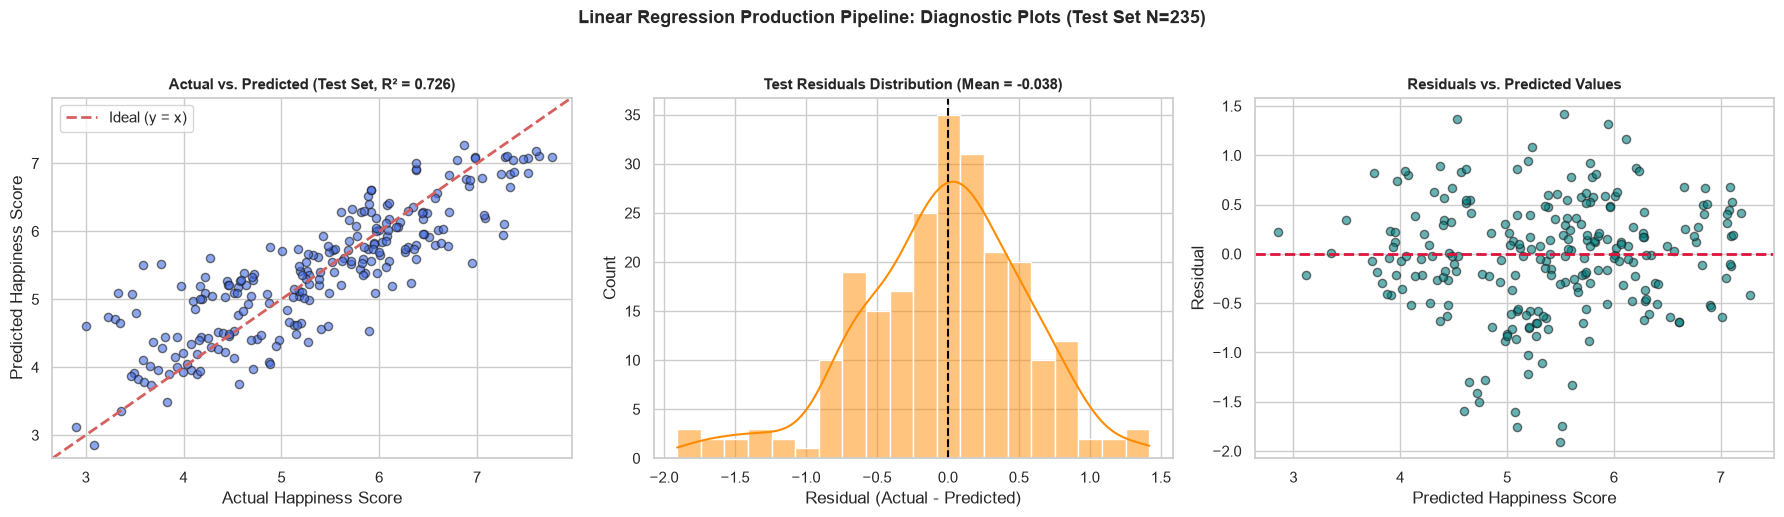

In [12]:
residuals_test = y_test - y_test_pred_lr

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs Predicted
axes[0].scatter(y_test, y_test_pred_lr, alpha=0.6, color="royalblue", edgecolors="k", s=35)
min_val = min(y_test.min(), y_test_pred_lr.min()) - 0.2
max_val = max(y_test.max(), y_test_pred_lr.max()) + 0.2
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2, label="Ideal (y = x)")
axes[0].set_title(f"Actual vs. Predicted (Test Set, R² = {metrics_table.loc[1, 'R2']:.3f})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Actual Happiness Score")
axes[0].set_ylabel("Predicted Happiness Score")
axes[0].legend()
axes[0].set_xlim(min_val, max_val)
axes[0].set_ylim(min_val, max_val)

# 2. Residual Histogram & KDE
sns.histplot(residuals_test, kde=True, bins=20, color="darkorange", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title(f"Test Residuals Distribution (Mean = {residuals_test.mean():.3f})", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Residual (Actual - Predicted)")
axes[1].set_ylabel("Count")

# 3. Residuals vs Predicted (Homoscedasticity check)
axes[2].scatter(y_test_pred_lr, residuals_test, alpha=0.6, color="teal", edgecolors="k", s=35)
axes[2].axhline(0, color="crimson", linestyle="--", linewidth=2)
axes[2].set_title("Residuals vs. Predicted Values", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Predicted Happiness Score")
axes[2].set_ylabel("Residual")

plt.suptitle("Linear Regression Production Pipeline: Diagnostic Plots (Test Set N=235)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### 4.6 Model Serialization (`models/model.pkl`)
We serialize the entire pipeline (`StandardScaler` + `LinearRegression`) to `models/model.pkl`.
Serializing the unified pipeline guarantees that whatever scaling transformations were fitted on `X_train` will automatically be applied to single incoming streaming records in Apache Kafka.

In [13]:
MODELS_DIR = Path("../models") if Path("../models").exists() else Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

model_output_path = MODELS_DIR / "model.pkl"

# Serialize pipeline using joblib
joblib.dump(production_pipeline, model_output_path)

print(f"Model pipeline successfully serialized to: {model_output_path.resolve()}")
print(f"File size: {model_output_path.stat().st_size} bytes")
assert model_output_path.exists(), "Model file was not created!"
assert model_output_path.stat().st_size > 0, "Model file is empty!"


Model pipeline successfully serialized to: C:\Users\juand\Desktop\mis_cosas\uao\etl\workshops\workshop-3\models\model.pkl
File size: 1601 bytes


### 4.7 Inference Smoke Test: Replicating Kafka Consumer Payload
To verify operational readiness for **Part B (Step 6 — Kafka Consumer)**, we reload `models/model.pkl` from disk and execute inference on an unscaled simulated streaming event matching the rubric specification.

In [14]:
# Reload serialized model pipeline
loaded_model = joblib.load(model_output_path)

# Simulated incoming event from Kafka producer (matching rubric JSON format)
simulated_event_payload = {
    "event_id": "E001",
    "country": "Colombia",
    "year": 2019,
    "gdp": 1.2,
    "family": 0.8,
    "health": 0.9,
    "freedom": 0.6,
    "generosity": 0.3,
    "corruption": 0.1,
    "actual_happiness_score": 6.2,
    "event_time": "2026-10-30T15:30:00"
}

# Consumer feature extraction using exact ordering contract
features_for_inference = pd.DataFrame([{
    col: simulated_event_payload[col] for col in FEATURE_NAMES
}])

print("Incoming raw feature vector extracted by consumer:")
display(features_for_inference)

# Run prediction through loaded pipeline (scaling applied internally)
predicted_score = float(loaded_model.predict(features_for_inference)[0])
actual_score = simulated_event_payload["actual_happiness_score"]
prediction_error = abs(actual_score - predicted_score)

print(f"Actual Happiness Score    : {actual_score:.4f}")
print(f"Predicted Happiness Score : {predicted_score:.4f}")
print(f"Absolute Prediction Error : {prediction_error:.4f}")

# Sanity assertion
assert 1.0 <= predicted_score <= 10.0, f"Unreasonable prediction: {predicted_score}"
print("\nSMOKE TEST PASSED: Pipeline is fully ready for Apache Kafka real-time streaming inference!")

Incoming raw feature vector extracted by consumer:


,gdp,family,health,freedom,generosity,corruption
0,1.2,0.8,0.9,0.6,0.3,0.1


Actual Happiness Score    : 6.2000
Predicted Happiness Score : 6.1129
Absolute Prediction Error : 0.0871

SMOKE TEST PASSED: Pipeline is fully ready for Apache Kafka real-time streaming inference!
